# Notebook 4 : le labo de simulation des méthodes de pricing

Ce notebook compare les méthodes de calcul du prix d'une option sur spread $\max(S_{1,T} - S_{2,T} - K,\ 0)$ **à l'intérieur d'un modèle** : les prix sont simulés par le modèle lui-même, donc on connaît la bonne réponse. Le réalisme du modèle se juge ailleurs, sur données réelles (notebooks 2 et 3).

Trois sections fixes, une par critère, et **une ligne par méthode** dans chacune :

| Section | Critère | Mesure |
|---|---|---|
| 1 | Justesse | erreur de prix (puis de deltas) par rapport à la référence, sur une grille de $K$, $\rho$, $T$ |
| 2 | Vitesse | millisecondes par prix et par paire de deltas |
| 3 | Couverture | couverture quotidienne sur 1000 chemins : P&L moyen, écart-type / prime, pire 5 % |

**Ajouter une méthode** (Kirk, Bjerksund–Stensland…) = l'écrire dans `src/` avec son test, puis ajouter une ligne dans les dictionnaires `price_methods` (section 1) et `delta_methods` (section 3), et relancer le notebook. Le reste ne change pas.

Méthodes présentes : Monte Carlo (100 000 scénarios, la méthode de base) et Margrabe ($K = 0$ seulement). Modèle : GBM bivarié.

## 0. Cas de base, grille et référence

Cas de base (fil rouge) : Brent 80 \$, WTI 75 \$, $\sigma_1 = 30$ %, $\sigma_2 = 35$ %, $r = 3$ %. La grille couvre la zone de nos données : $\rho$ de 0,7 à 0,97 (Brent/WTI hors 2020), $K$ de 0 à 10 \$ autour du spread, 3 mois et 1 an.

**Référence** : Margrabe quand $K = 0$ (formule exacte) ; sinon un Monte Carlo de 10 millions de scénarios, cinq paquets de 2 millions avec des graines différentes, dont on fait la moyenne. Son erreur standard est environ 10 fois plus petite que celle d'un Monte Carlo à 100 000 scénarios.

In [1]:
import itertools
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spread_options.analytics import margrabe_call, margrabe_deltas
from spread_options.hedging import delta_hedge_spread_pnl
from spread_options.models import simulate_bivariate_gbm_paths
from spread_options.monte_carlo import mc_spread_call
from spread_options.products import spread_call_payoff

S1_0, S2_0, r = 80.0, 75.0, 0.03
sigma1, sigma2 = 0.30, 0.35
grid = list(itertools.product([0.0, 5.0, 10.0], [0.70, 0.85, 0.97], [0.25, 1.0])) # (K, rho, T): 18 points

def reference_price(K, rho, T):
    # exact Margrabe price if K = 0, else the mean of 5 Monte Carlo runs of 2 million paths
    if K == 0:
        return margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho), 0.0
    runs = [mc_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho, n_paths=2_000_000, seed=s)
            for s in range(101, 106)] # 5 different seeds
    prices = [p for p, _ in runs]
    std_err = np.mean([e for _, e in runs]) / np.sqrt(len(runs)) # 5 independent runs: error / sqrt(5)
    return np.mean(prices), std_err

reference = {point: reference_price(*point) for point in grid} # about 10 s
print(f"{len(grid)} grid points; reference at K = 5, rho = 0.85, T = 1: "
      f"{reference[(5.0, 0.85, 1.0)][0]:.4f} +/- {reference[(5.0, 0.85, 1.0)][1]:.4f} $")

18 grid points; reference at K = 5, rho = 0.85, T = 1: 5.6283 +/- 0.0026 $


## 1. Justesse

Chaque méthode est une fonction `(K, rho, T) -> prix`. Une méthode qui ne s'applique pas à un point de la grille renvoie `nan` (Margrabe pour $K \neq 0$).

In [2]:
price_methods = {
    "Monte Carlo 100k": lambda K, rho, T: mc_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho)[0],
    "Margrabe": lambda K, rho, T: margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho) if K == 0 else np.nan,
}

rows = []
for (K, rho, T) in grid:
    ref, ref_err = reference[(K, rho, T)]
    for name, price_fn in price_methods.items():
        price = price_fn(K, rho, T)
        rows.append(dict(method=name, K=K, rho=rho, T=T, reference=ref, price=price, error=price - ref))
errors = pd.DataFrame(rows)

# one line per method: how far from the reference, on the points where it applies
summary_accuracy = errors.dropna().groupby("method").agg(
    points=("error", "size"),
    mean_abs_error=("error", lambda e: e.abs().mean()),
    max_abs_error=("error", lambda e: e.abs().max()),
)
summary_accuracy.round(4)

,points,mean_abs_error,max_abs_error
method,,,
Margrabe,6,0.0000,0.0000
Monte Carlo 100k,18,0.0288,0.0773


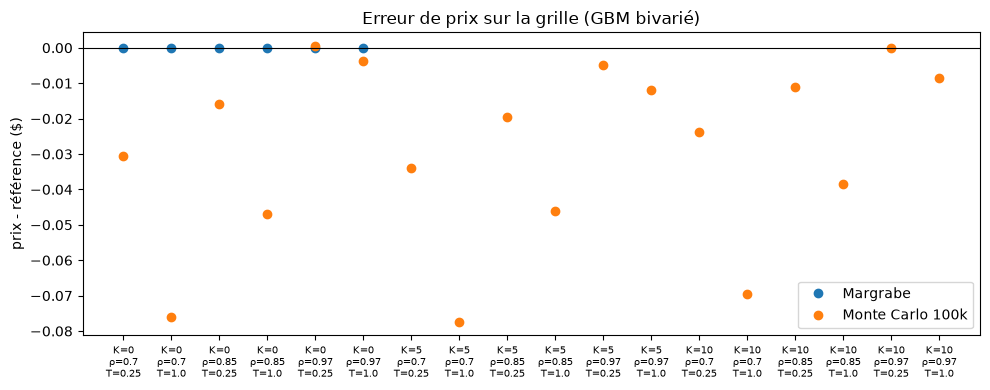

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
errors["point"] = [grid.index((K, rho, T)) for K, rho, T in zip(errors["K"], errors["rho"], errors["T"])]
for name, group in errors.dropna().groupby("method"):
    ax.plot(group["point"], group["error"], "o", label=name) # x = position of the point in the grid
labels = [f"K={K:.0f}\nρ={rho}\nT={T}" for (K, rho, T) in grid]
ax.set_xticks(range(len(grid)))
ax.set_xticklabels(labels, fontsize=7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("prix - référence ($)")
ax.set_title("Erreur de prix sur la grille (GBM bivarié)")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** Margrabe est exacte : c'est la référence à $K = 0$ (le test `test_zero_strike_spread_call_matches_margrabe` vérifie qu'elle coïncide avec le Monte Carlo). Elle ne couvre que 6 points sur 18. Le Monte Carlo à 100 000 scénarios couvre toute la grille avec une erreur moyenne de quelques centimes, qui n'est que son bruit.

Les erreurs du Monte Carlo vont presque toutes dans le même sens. Tous les points utilisent la même graine (23), donc les mêmes tirages : si ces tirages sont un peu « bas », tous les prix le sont. C'est utile pour les deltas, car deux prix voisins calculés avec les mêmes tirages ont la même erreur, qui disparaît dans la différence.

*Erreur de deltas : à venir.* La référence pour $K \neq 0$ demande une fonction de deltas par Monte Carlo (`mc_spread_deltas`, prochaine brique de la librairie).

## 2. Vitesse

Temps moyen d'un appel, au cas de base ($K = 5$ pour le Monte Carlo, $K = 0$ pour Margrabe), mesuré sur des centaines d'appels.

In [4]:
def ms_per_call(fn, n_calls):
    start = time.perf_counter()
    for _ in range(n_calls):
        fn()
    return (time.perf_counter() - start) / n_calls * 1000 # milliseconds

speed = pd.DataFrame([
    dict(method="Monte Carlo 100k",
         ms_per_price=ms_per_call(lambda: mc_spread_call(S1_0, S2_0, 5.0, 1.0, r, sigma1, sigma2, 0.6), 50),
         ms_per_deltas=np.nan), # needs mc_spread_deltas
    dict(method="Margrabe",
         ms_per_price=ms_per_call(lambda: margrabe_call(S1_0, S2_0, 1.0, sigma1, sigma2, 0.6), 5000),
         ms_per_deltas=ms_per_call(lambda: margrabe_deltas(S1_0, S2_0, 1.0, sigma1, sigma2, 0.6), 5000)),
]).set_index("method")
# a daily hedge of 1000 paths needs 252 000 pairs of deltas
speed["hedge_1000_paths_min"] = speed["ms_per_deltas"] * 252_000 / 1000 / 60
speed.round(3)

,ms_per_price,ms_per_deltas,hedge_1000_paths_min
method,,,
Monte Carlo 100k,5.665,NaN,NaN
Margrabe,0.101,0.089,0.375


**Lecture.** Margrabe est environ 65 fois plus rapide que le Monte Carlo par prix. Une couverture quotidienne de 1000 chemins demande 252 000 paires de deltas : un peu moins d'une demi-minute avec Margrabe. Avec des deltas Monte Carlo (deux prix par delta, deux deltas), il faudrait de l'ordre de 100 minutes. C'est la raison d'être des méthodes rapides.

## 3. Couverture

Produit : l'option d'échange ($K = 0$) du cas de base, $\rho = 0{,}6$, un an, vendue au prix de la méthode et couverte chaque jour avec ses deltas, sur 1000 chemins simulés par le GBM bivarié (le modèle est vrai). Repère : le call de la partie 1 du notebook 1 donne 4,8 % de la prime.

In [5]:
rho, T = 0.6, 1.0
obs_times = np.linspace(0, T, 253) # daily rebalancing
paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho, obs_times, n_paths=1000)

# one entry per method: (price sold, delta function)
delta_methods = {
    "Margrabe": (margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho),
                 lambda S1, S2, time_left: margrabe_deltas(S1, S2, time_left, sigma1, sigma2, rho)),
}

hedge_pnl = {}
for name, (price0, deltas_fn) in delta_methods.items():
    hedge_pnl[name] = delta_hedge_spread_pnl(paths1, paths2, T, r, price0, deltas_fn,
                                             lambda S1T, S2T: spread_call_payoff(S1T, S2T, 0.0))

hedging = pd.DataFrame([
    dict(method=name, premium=delta_methods[name][0], mean_pnl=pnl.mean(), std_pnl=pnl.std(),
         std_over_premium=pnl.std() / delta_methods[name][0], worst_5pct=np.quantile(pnl, 0.05))
    for name, pnl in hedge_pnl.items()
]).set_index("method")
hedging.round(3)

,premium,mean_pnl,std_pnl,std_over_premium,worst_5pct
method,,,,,
Margrabe,11.776,0.017,0.549,0.047,-0.854


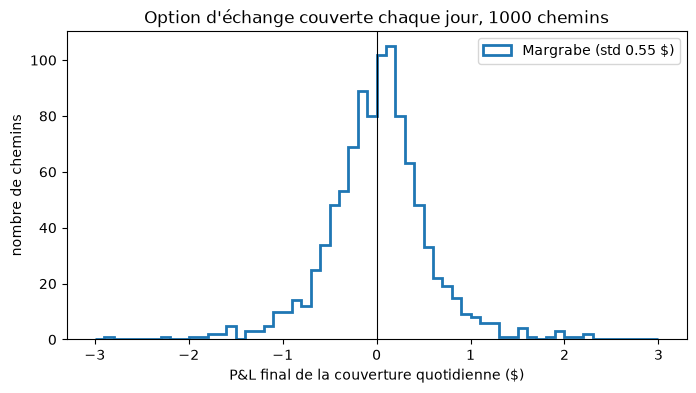

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-3, 3, 61)
for name, pnl in hedge_pnl.items():
    ax.hist(pnl, bins=bins, histtype="step", linewidth=2, label=f"{name} (std {pnl.std():.2f} $)")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("P&L final de la couverture quotidienne ($)")
ax.set_ylabel("nombre de chemins")
ax.set_title("Option d'échange couverte chaque jour, 1000 chemins")
ax.legend()
plt.show()

**Lecture.** Le P&L moyen est proche de 0, donc le prix de Margrabe est le bon coût de couverture. L'écart-type vaut 4,7 % de la prime, comme le call (4,8 %) : couvrir deux actifs au lieu d'un ne coûte rien en précision quand les deltas sont exacts. La ligne Monte Carlo viendra avec `mc_spread_deltas`.

## Synthèse

| Méthode | Points de la grille | Erreur de prix | ms / prix | ms / deltas | Couverture : std / prime | Pratique des desks |
|---|---|---|---|---|---|---|
| Monte Carlo 100k | 18 / 18 | quelques centimes (son bruit) | ≈ 6 | à venir | à venir | produits sans formule ; trop lent pour un portefeuille entier |
| Margrabe | 6 / 18 ($K = 0$) | 0 (exacte) | ≈ 0,09 | ≈ 0,09 | 4,7 % | base de la formule de Kirk |

Suite : `mc_spread_deltas` (deltas Monte Carlo, pour compléter la ligne Monte Carlo et servir de référence des deltas), puis Kirk, la formule la plus utilisée par les desks.